# HA1 — Graded abstractness simulator

**Xia Yuqi's working submission; 20 Chinese + 20 English senses.** The instructor accepted the bilingual 40-row scope. Source: `data/final/spatial_relations_zh20_en20_v1.csv`. C ratings combine one PR #12 pass, PR #11 drafts, and two initial estimates; S paths are reported from PR #12. This notebook calculates and visualizes them, but does not claim independent team agreement.

Run all cells from any directory inside the repository. The notebook saves a 40-row derived table and two figures in this folder.

**Version boundary:** A newer C re-audit in PR #14 is under review with Hu Jinnan's requested changes. The calculations below remain a reproducible **main-v1 baseline**, not an adoption of that draft. See `TEAM_REVIEW_UPDATE.md`.

In [1]:
from pathlib import Path
import platform, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

current = Path.cwd().resolve()
repo = next((p for p in (current, *current.parents)
             if (p / "data/final/spatial_relations_zh20_en20_v1.csv").is_file()), None)
if repo is None:
    raise FileNotFoundError("Open the notebook inside the repository or run it from the repository root")
work = repo / "assignments/xiayuqi"
sys.path.insert(0, str(work))
from ha1_model import (
    FEATURES, abstractness, add_weight_settings, compute_c_raw, compute_s_raw,
    crossing_pairs, load_inventory, prepare_scores, scatter_plot, weight_sensitivity_plot
)
print("Python", platform.python_version(), "| NumPy", np.__version__,
      "| pandas", pd.__version__)
print("Repository:", repo)

Python 3.13.14 | NumPy 2.5.3 | pandas 3.0.5
Repository: E:\Data Science\DS_2\7_Embodied AI and Neurocomputional Semantics\history_rewrite_repo


## 1. Separate C and S

`C_raw` is the **mean** of the seven 0–2 feature values. `S_raw` counts edges in the reported root-to-sense path. A missing path yields **NA**, never zero. Each axis is then scaled by observed min–max to [0, 1]. The scale is dataset-relative: adding different concepts can move existing normalized positions.

In [2]:
inventory = load_inventory(repo / "data/final/spatial_relations_zh20_en20_v1.csv")
scores = add_weight_settings(prepare_scores(inventory, c_aggregation="mean"))
display(scores[["concept_id","language","term","C_raw","C_norm","S_raw","S_norm",
                "quadrant","A_0.2","A_0.5","A_0.8"]].head(10))
print("C raw range:", scores.C_raw.min(), "to", scores.C_raw.max())
print("S raw range:", scores.S_raw.min(), "to", scores.S_raw.max())
print("S missing:", scores.S_raw.isna().sum(), "of", len(scores))

,concept_id,language,term,C_raw,C_norm,S_raw,S_norm,quadrant,A_0.2,A_0.5,A_0.8
0,ZH01,ZH,位置,1.000000,1.0,3.0,0.0,high_C_low_S,0.80,0.5,0.20
1,ZH02,ZH,内部,0.571429,0.4,5.0,0.4,low_C_low_S,0.60,0.6,0.60
2,ZH03,ZH,外部,0.714286,0.6,NaN,NaN,NA_S,NaN,NaN,NaN
3,ZH04,ZH,边界,0.571429,0.4,5.0,0.4,low_C_low_S,0.60,0.6,0.60
4,ZH05,ZH,中心,0.571429,0.4,5.0,0.4,low_C_low_S,0.60,0.6,0.60
5,ZH06,ZH,前面,0.571429,0.4,6.0,0.6,low_C_high_S,0.44,0.5,0.56
6,ZH07,ZH,左侧,1.000000,1.0,6.0,0.6,high_C_high_S,0.32,0.2,0.08
7,ZH08,ZH,坡度,0.714286,0.6,5.0,0.4,high_C_low_S,0.56,0.5,0.44
8,ZH09,ZH,上方,0.428571,0.2,NaN,NaN,NA_S,NaN,NaN,NaN
9,ZH10,ZH,下方,0.428571,0.2,NaN,NaN,NA_S,NaN,NaN,NaN


C raw range: 0.2857142857142857 to 1.0
S raw range: 3.0 to 8.0
S missing: 14 of 40


In [3]:
# Calculation checks: path depth, seven scores, normalization, and NA propagation.
assert np.allclose(scores.C_raw, scores[list(FEATURES)].mean(axis=1))
assert np.allclose(scores.C_norm.min(), 0) and np.allclose(scores.C_norm.max(), 1)
assert np.allclose(scores.S_norm.min(), 0) and np.allclose(scores.S_norm.max(), 1)
assert scores.S_raw.isna().sum() == 14
assert scores.loc[scores.S_raw.isna(), ["S_norm","A_0.2","A_0.5","A_0.8"]].isna().all().all()
print("All calculation checks passed.")

All calculation checks passed.


## 2. C×S plane

The dashed dividers are at **0.5 on the normalized axes**. Only the 26 senses with a supported S path appear. The 14 remaining rows stay in the exported table with S and A missing. IDs on the figure match the table.

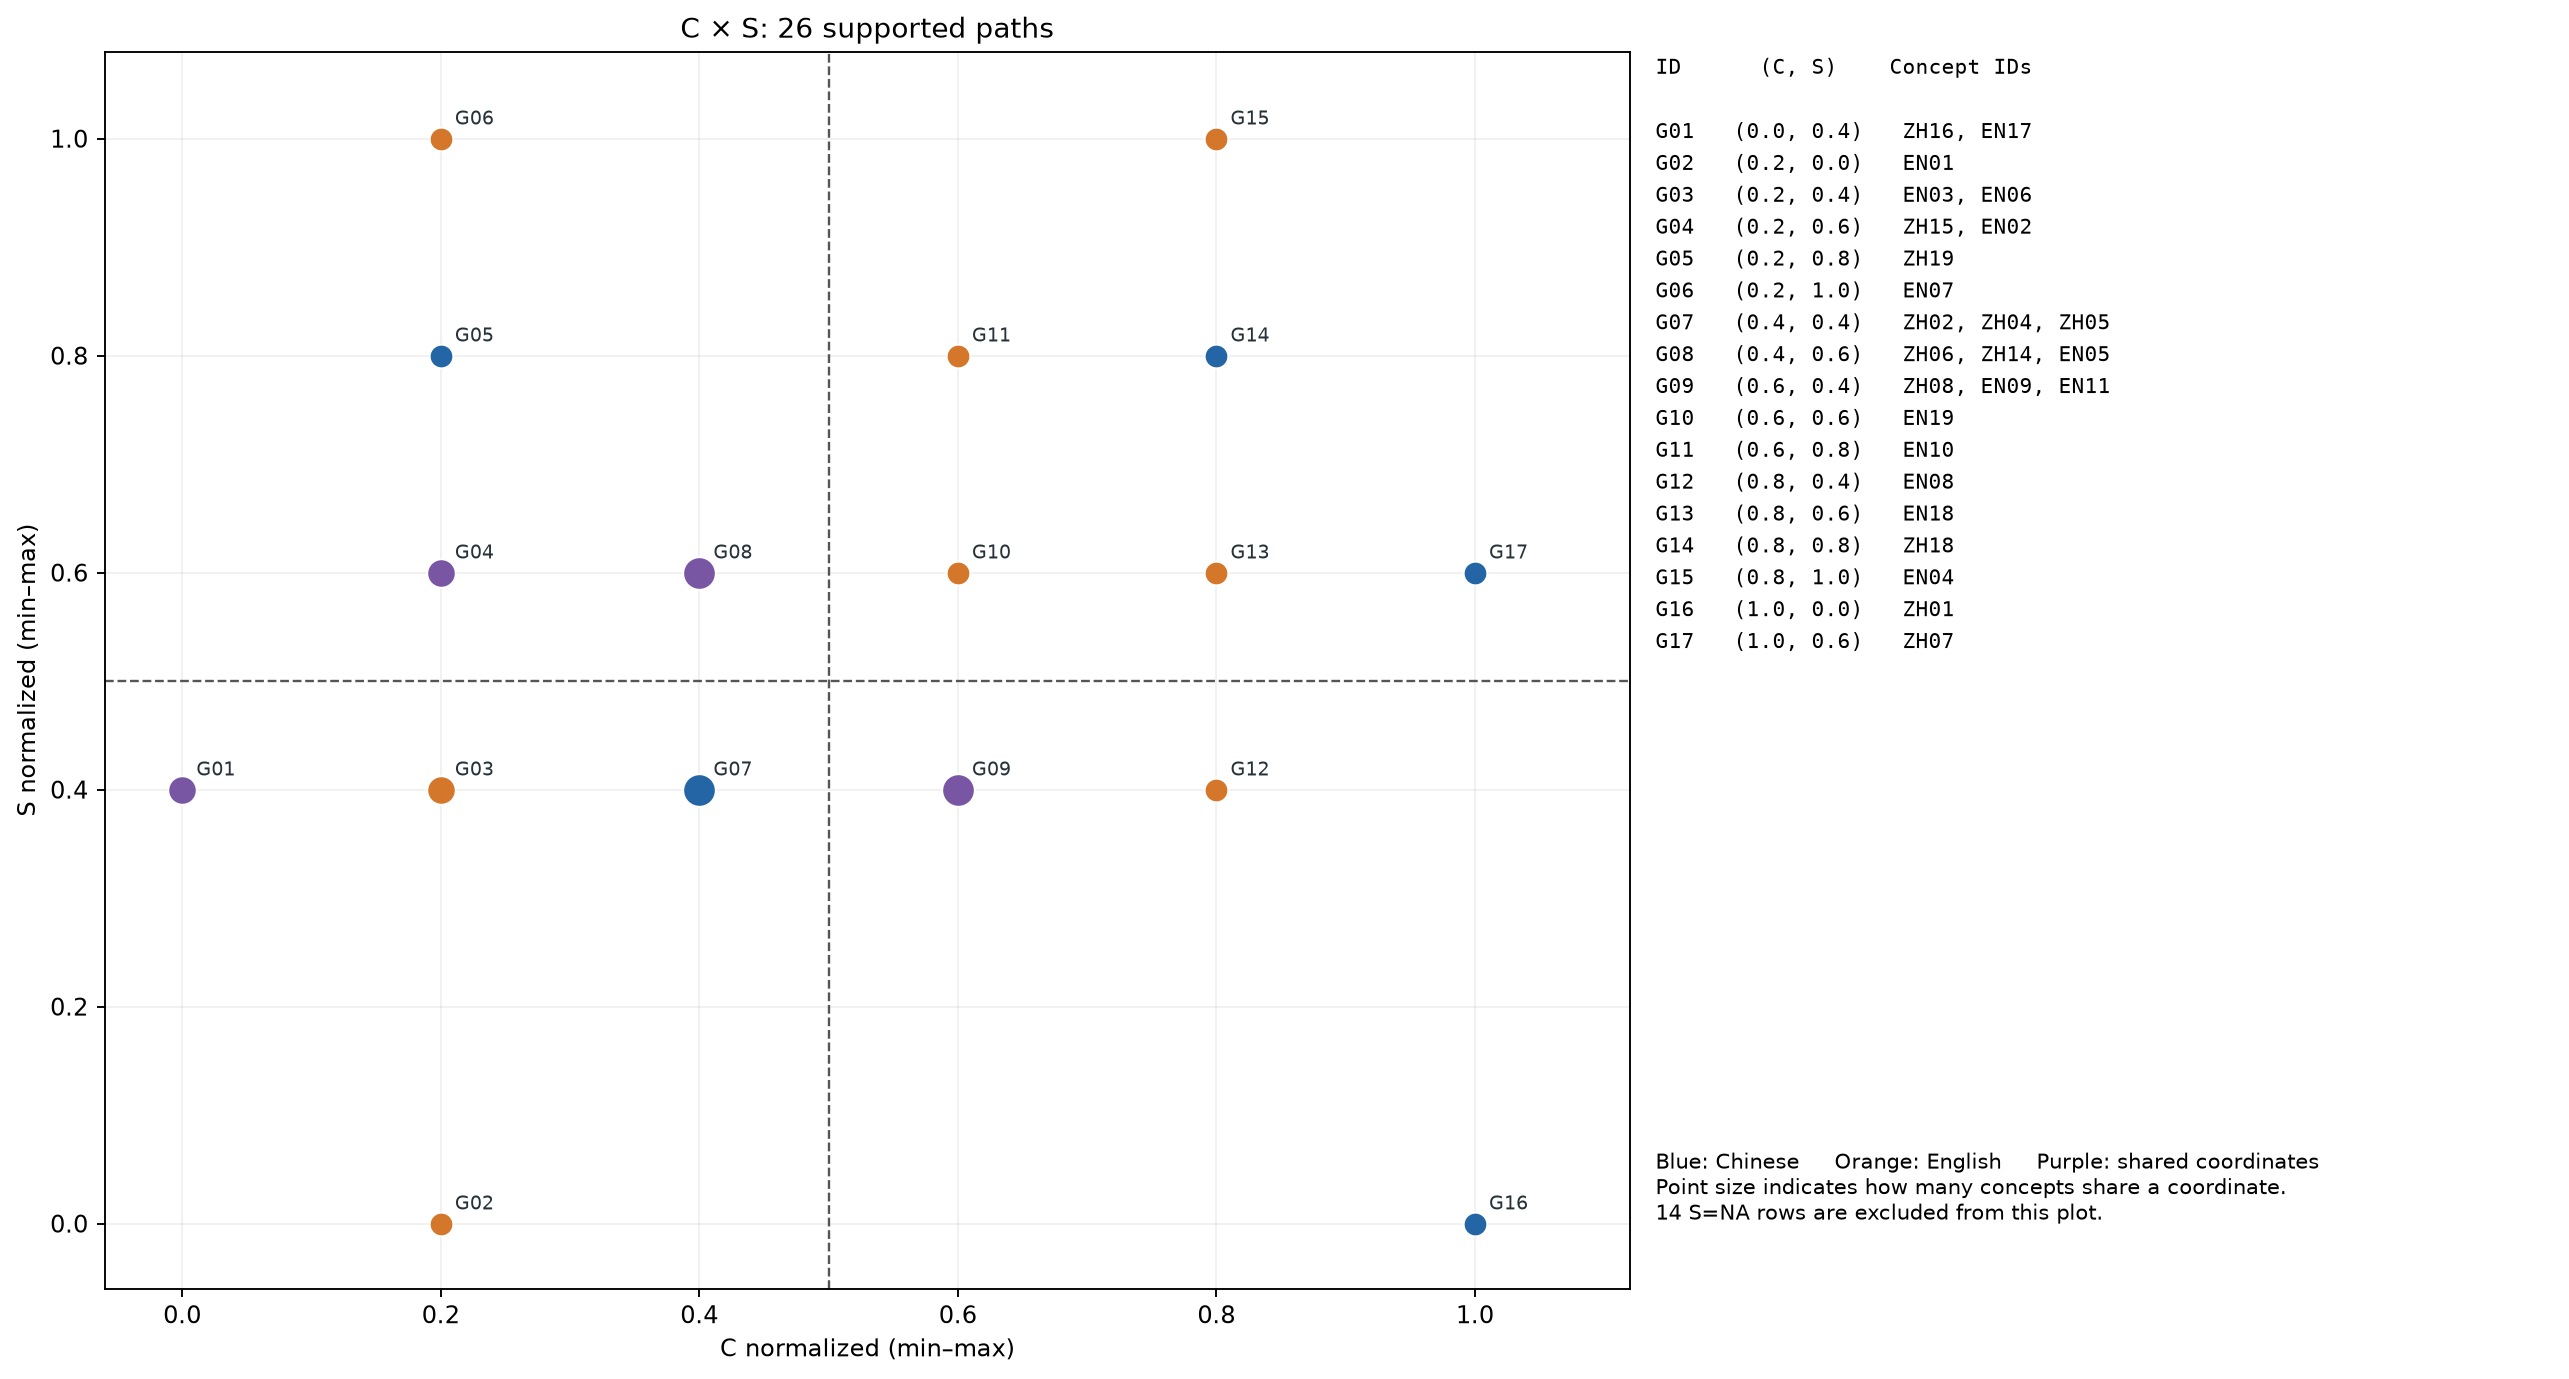

quadrant,low_C_low_S,low_C_high_S,high_C_low_S,high_C_high_S,NA_S
language,,,,,
EN,4,3,3,4,6
ZH,4,4,2,2,8


In [4]:
scatter_file = work / "figures/cs_scatter_ha1.png"
scatter_plot(scores, scatter_file)
display(Image(filename=str(scatter_file)))
display(pd.crosstab(scores.language, scores.quadrant).reindex(
    columns=["low_C_low_S","low_C_high_S","high_C_low_S","high_C_high_S","NA_S"],
    fill_value=0))

## 3. Adjustable composite

The function below accepts any `w` from 0 to 1. It always reports the two axes beside `A(w)=w(1-C_norm)+(1-w)(1-S_norm)`. The required settings 0.2, 0.5, and 0.8 are saved in the output table. `w=1` and `w=0` are C-only and S-only comparison baselines, not independent validity tests.

In [5]:
def show_weight(w=0.5, top_n=10):
    table = scores[["concept_id","language","term","C_norm","S_norm"]].copy()
    table["A"] = abstractness(scores, w)
    return table.dropna(subset=["A"]).sort_values("A", ascending=False).head(top_n)

display(show_weight(0.5))
# Optional live slider in Jupyter:
# from ipywidgets import interact, FloatSlider
# interact(show_weight, w=FloatSlider(value=0.5, min=0, max=1, step=0.1))

,concept_id,language,term,C_norm,S_norm,A
20,EN01,EN,location,0.2,0.0,0.9
15,ZH16,ZH,路径,0.0,0.4,0.8
36,EN17,EN,path,0.0,0.4,0.8
25,EN06,EN,gap,0.2,0.4,0.7
22,EN03,EN,center,0.2,0.4,0.7
21,EN02,EN,boundary,0.2,0.6,0.6
14,ZH15,ZH,空隙,0.2,0.6,0.6
3,ZH04,ZH,边界,0.4,0.4,0.6
4,ZH05,ZH,中心,0.4,0.4,0.6
1,ZH02,ZH,内部,0.4,0.4,0.6


## 4. Sensitivity and error analysis

Every concept with S has a line for `w=0,0.1,…,1`. A concept is flagged as weight-sensitive if its A changes by more than 0.1 between 0.2 and 0.8. Pairwise crossings count rank reversals between those two settings. We also compare the C aggregation rule: mean versus sum, max, and the number of nonzero channels.

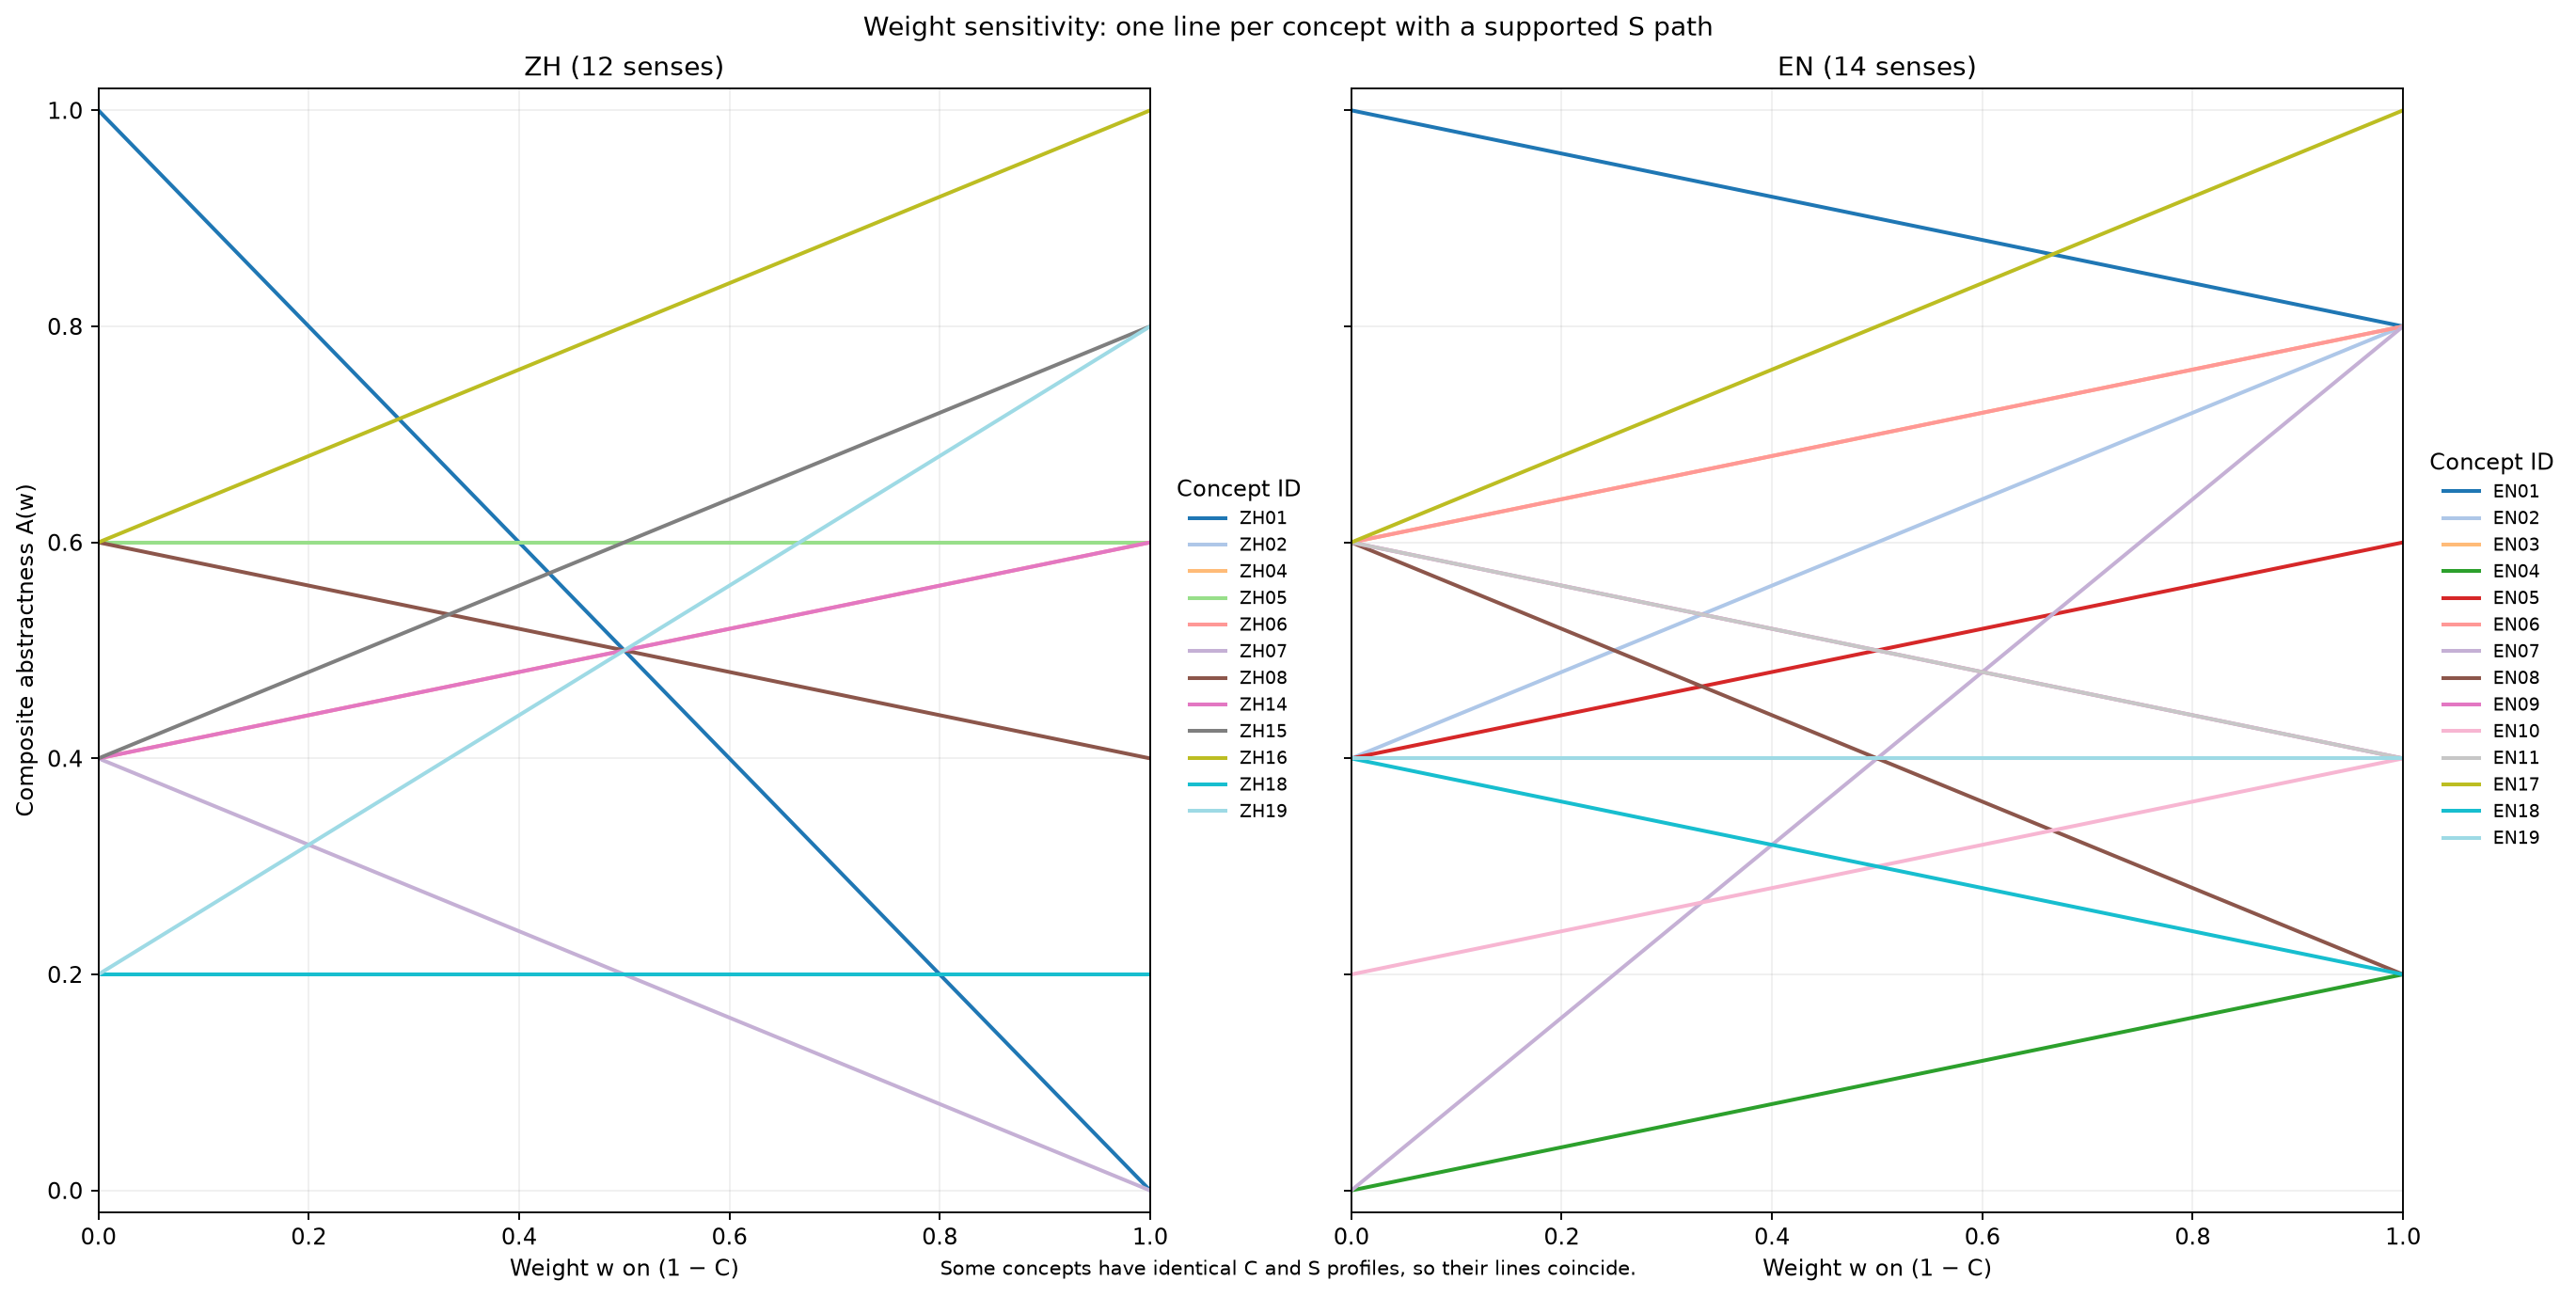

Weight-sensitive senses (>0.1): 21 of 26
Pairwise rank crossings: 82


,concept_id,term,C_norm,S_norm,A_0.2,A_0.8,weight_change
0,ZH01,位置,1.0,0.0,0.80,0.20,0.60
26,EN07,adjacency,0.2,1.0,0.16,0.64,0.48
18,ZH19,对称,0.2,0.8,0.32,0.68,0.36
36,EN17,path,0.0,0.4,0.68,0.92,0.24
15,ZH16,路径,0.0,0.4,0.68,0.92,0.24
6,ZH07,左侧,1.0,0.6,0.32,0.08,0.24
21,EN02,boundary,0.2,0.6,0.48,0.72,0.24
14,ZH15,空隙,0.2,0.6,0.48,0.72,0.24


Every fragile sense has a one-sentence explanation: True


In [6]:
sensitivity_file = work / "figures/weight_sensitivity_ha1.png"
weight_sensitivity_plot(scores, sensitivity_file)
display(Image(filename=str(sensitivity_file)))
valid = scores.dropna(subset=["S_norm"]).copy()
valid["weight_change"] = (valid["A_0.8"] - valid["A_0.2"]).abs()
print("Weight-sensitive senses (>0.1):", (valid.weight_change > 0.1).sum(), "of", len(valid))
print("Pairwise rank crossings:", len(crossing_pairs(scores)))
display(valid[["concept_id","term","C_norm","S_norm","A_0.2","A_0.8","weight_change"]]
        .sort_values("weight_change", ascending=False).head(8))
valid["fragile"] = valid["weight_change"] > 0.1
def explain_weight_change(row):
    if abs(row.C_norm - row.S_norm) < 1e-10:
        return "A stays constant because normalized C and S are equal."
    direction = "rises" if row.C_norm < row.S_norm else "falls"
    relation = "lower" if row.C_norm < row.S_norm else "higher"
    return (f"A {direction} by {row.weight_change:.2f} from w=0.2 to 0.8 because "
            f"normalized C is {relation} than normalized S for this target sense.")
valid["one_sentence_reason"] = valid.apply(explain_weight_change, axis=1)
print("Every fragile sense has a one-sentence explanation:", 
      valid.loc[valid.fragile, "one_sentence_reason"].notna().all())


In [7]:
sum_scaled = prepare_scores(inventory, c_aggregation="sum")
active_scaled = prepare_scores(inventory, c_aggregation="active_count")
max_raw = compute_c_raw(inventory, aggregation="max")
print("Mean vs sum normalized C, largest absolute difference:",
      (scores.C_norm - sum_scaled.C_norm).abs().max())
print("Max aggregation unique raw values:", sorted(max_raw.unique()),
      "— min–max scaling is undefined when all are equal.")
print("Mean vs active-channel-count Spearman rho:",
      scores.C_norm.corr(active_scaled.C_norm, method="spearman"))
print("Quadrant changes with active-channel-count C:",
      (scores.quadrant != active_scaled.quadrant).sum())
print("A(0.5) rank association with C-only:",
      scores["A_0.5"].corr(abstractness(scores, 1), method="spearman"))
print("A(0.5) rank association with S-only:",
      scores["A_0.5"].corr(abstractness(scores, 0), method="spearman"))

Mean vs sum normalized C, largest absolute difference: 1.1102230246251565e-16
Max aggregation unique raw values: [np.float64(2.0)] — min–max scaling is undefined when all are equal.


Mean vs active-channel-count Spearman rho: 0.9347361367076299
Quadrant changes with active-channel-count C: 5
A(0.5) rank association with C-only: 0.7895317169182787
A(0.5) rank association with S-only: 0.6641044239414158


### Known taxonomy mismatch scenario

Chen's draft PR #14 and Hu's review agree that the reported S path for `EN19 balance` does not match a **narrowed bodily upright** sense. The published main-v1 target is broader, so the primary baseline above remains unchanged. This diagnostic removes only that disputed path, leaves C untouched, and shows how much the C×S result depends on that one S assumption. It does **not** accept the rest of PR #14.

In [8]:
balance_na_input = inventory.copy()
balance_na_input.loc[balance_na_input.concept_id == "EN19", ["S_depth","S_taxonomy_path"]] = np.nan
balance_na = prepare_scores(balance_na_input)
comparison = pd.concat([
    scores.quadrant.value_counts().rename("main_v1"),
    balance_na.quadrant.value_counts().rename("EN19_S_NA_scenario")
], axis=1).fillna(0).astype(int)
display(comparison)
print("This is a disputed-path sensitivity check, not an approved dataset revision.")

,main_v1,EN19_S_NA_scenario
quadrant,,
NA_S,14,15
low_C_low_S,8,8
low_C_high_S,7,7
high_C_high_S,6,5
high_C_low_S,5,5


This is a disputed-path sensitivity check, not an approved dataset revision.


## 5. Export

The derived CSV preserves all 40 rows, including the 14 with S=NA, and records raw and normalized values plus the three required composite settings. The plots are saved as PNGs for direct submission or presentation.

In [9]:
output = work / "ha1_scores_zh20_en20.csv"
export_cols = ["concept_id","language","term","semantic_family","C_rating_source",
               "C_raw","C_norm","S_raw","S_norm","S_source","quadrant",
               "A_0.2","A_0.5","A_0.8"]
scores[export_cols].to_csv(output, index=False, encoding="utf-8", float_format="%.6f")
print("Saved:", output.relative_to(repo))
print("Saved:", scatter_file.relative_to(repo))
print("Saved:", sensitivity_file.relative_to(repo))
sensitivity_output = work / "ha1_weight_sensitivity_details.csv"
valid[["concept_id","language","term","C_norm","S_norm","A_0.2","A_0.8",
       "weight_change","fragile","one_sentence_reason"]].to_csv(
    sensitivity_output, index=False, encoding="utf-8", float_format="%.6f")
print("Saved:", sensitivity_output.relative_to(repo))


Saved: assignments\xiayuqi\ha1_scores_zh20_en20.csv
Saved: assignments\xiayuqi\figures\cs_scatter_ha1.png
Saved: assignments\xiayuqi\figures\weight_sensitivity_ha1.png
Saved: assignments\xiayuqi\ha1_weight_sensitivity_details.csv


# HA1 interpretation — Xia Yuqi

The simulator keeps sensorimotor grounding (C) and taxonomic specificity (S) separate before forming an abstractness score. Raw C is the mean of seven 0–2 channel ratings. For 26 senses with a documented path, raw S counts taxonomy edges. Both axes receive dataset-level min–max scaling. The 14 senses without a supported path retain S=NA and have no composite score; assigning zero would falsely make them broad categories.

The normalized C×S plot contains eight low-C/low-S, seven low-C/high-S, five high-C/low-S, and six high-C/high-S senses. This spread is descriptive, not evidence of balanced human semantic representation. The raw ranges are C=0.286–1.000 and S=3–8. Different inventory choices could move concepts across the 0.5 dividers. Chinese supplies 12 plotted senses and leaves eight S values missing; English supplies 14 and leaves six missing. Removing the disputed balance S path leaves five high-C/high-S senses and raises S=NA to 15. These coverage limits constrain interpretation.

Weight sensitivity is substantial. Between w=0.2 and w=0.8, 21 of 26 scorable senses change A by more than 0.1, and 82 pairs reverse rank. ZH01 (position) has maximal C but minimal S, so A changes by 0.60. EN07 (adjacency) shows the opposite pattern and changes by 0.48. A single ranking therefore needs both axes and a stated weight.

Two other choices matter. Mean and sum C normalize identically because they differ by a constant factor. Maximum-channel C fails: every concept's maximum is two, leaving no variation. Counting active channels changes five quadrants. The noun path receives the lowest normalized C despite possible motor associations; this reflects the chosen literal route sense and rating policy.

This is exploratory, not a validated human measurement. Ratings mix imported and draft values; S paths lack independent audit. A newer team re-audit remains under review. Independent ratings, sense verification, and another S definition remain necessary; no held-out accuracy is claimed without labels.
